# **National Institute of Justice Recidivism Challenge**
# Assignment 2: The Data 
*Instuctor Copy*

In your groups, use this file to upload and clean the NIJ data. Then perform a simple EDA to gain a better understanding of the data. After completing your EDA write a short response explaining your gleanings from the visualizations, include any hypotheses, questions, or surprising information you might have. 

Submit this file when finished, ensure your code has comments throughout and the project is organized neatly.

Remember while cleaning your data that its ultimate purpose will be for machine learning.

<h5>Data</h5>

https://catalog.data.gov/dataset/nijs-recidivism-challenge-full-dataset

<h2>Prep Work Station</h2>

In [2]:
#Importing libraries
import numpy as np 
import pandas as pd 
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
#Importing data as a pandas dataframe: df
df = pd.read_csv('NIJ_s_Recidivism_Challenge_Full_Dataset.csv')

In [4]:
#Looking at the first 10 lines of code
df.head(10)

,ID,Gender,Race,Age_at_Release,Residence_PUMA,Gang_Affiliated,Supervision_Risk_Score_First,Supervision_Level_First,Education_Level,Dependents,...,DrugTests_Meth_Positive,DrugTests_Other_Positive,Percent_Days_Employed,Jobs_Per_Year,Employment_Exempt,Recidivism_Within_3years,Recidivism_Arrest_Year1,Recidivism_Arrest_Year2,Recidivism_Arrest_Year3,Training_Sample
0,1,M,BLACK,43-47,16,False,3.0,Standard,At least some college,3 or more,...,0.000000,0.0,0.488562,0.447610,False,False,False,False,False,1
1,2,M,BLACK,33-37,16,False,6.0,Specialized,Less than HS diploma,1,...,0.000000,0.0,0.425234,2.000000,False,True,False,False,True,1
2,3,M,BLACK,48 or older,24,False,7.0,High,At least some college,3 or more,...,0.166667,0.0,0.000000,0.000000,False,True,False,True,False,1
3,4,M,WHITE,38-42,16,False,7.0,High,Less than HS diploma,1,...,0.000000,0.0,1.000000,0.718996,False,False,False,False,False,1
4,5,M,WHITE,33-37,16,False,4.0,Specialized,Less than HS diploma,3 or more,...,0.058824,0.0,0.203562,0.929389,False,True,True,False,False,1
5,6,M,WHITE,38-42,17,False,5.0,Standard,High School Diploma,0,...,0.000000,0.0,0.674252,0.307838,False,False,False,False,False,0
6,7,M,BLACK,48 or older,18,False,2.0,Standard,Less than HS diploma,2,...,0.000000,0.0,0.000000,0.000000,False,True,False,False,True,1
7,8,M,BLACK,38-42,16,False,5.0,High,High School Diploma,3 or more,...,0.000000,0.0,0.469446,0.525162,False,False,False,False,False,0
8,9,F,BLACK,43-47,5,NaN,7.0,High,High School Diploma,0,...,NaN,NaN,0.000000,0.000000,True,True,True,False,False,1
9,10,M,BLACK,43-47,16,False,5.0,Standard,High School Diploma,3 or more,...,0.000000,0.0,0.359712,1.000000,False,True,True,False,False,1


<h2>Cleaning</h2>

From observation, I can see some initial steps to take in cleaning this data. They are to: 
1) Remove the race and gender columns to prevent any bias in our MLM
3) Remove Training Label znd Recdivism years so MLM does not use it in its predictions
5) Check remaining for correct data types


In [47]:
#Removing Gender, Race, and Training Sample columns
clean_df = df.drop(columns=['Gender', 'Race', 'Training_Sample'])
clean_df.head(11)

,ID,Age_at_Release,Residence_PUMA,Gang_Affiliated,Supervision_Risk_Score_First,Supervision_Level_First,Education_Level,Dependents,Prison_Offense,Prison_Years,...,DrugTests_Cocaine_Positive,DrugTests_Meth_Positive,DrugTests_Other_Positive,Percent_Days_Employed,Jobs_Per_Year,Employment_Exempt,Recidivism_Within_3years,Recidivism_Arrest_Year1,Recidivism_Arrest_Year2,Recidivism_Arrest_Year3
0,1,43-47,16,False,3.0,Standard,At least some college,3 or more,Drug,More than 3 years,...,0.0,0.000000,0.0,0.488562,0.447610,False,False,False,False,False
1,2,33-37,16,False,6.0,Specialized,Less than HS diploma,1,Violent/Non-Sex,More than 3 years,...,0.0,0.000000,0.0,0.425234,2.000000,False,True,False,False,True
2,3,48 or older,24,False,7.0,High,At least some college,3 or more,Drug,1-2 years,...,0.0,0.166667,0.0,0.000000,0.000000,False,True,False,True,False
3,4,38-42,16,False,7.0,High,Less than HS diploma,1,Property,1-2 years,...,0.0,0.000000,0.0,1.000000,0.718996,False,False,False,False,False
4,5,33-37,16,False,4.0,Specialized,Less than HS diploma,3 or more,Violent/Non-Sex,1-2 years,...,0.0,0.058824,0.0,0.203562,0.929389,False,True,True,False,False
5,6,38-42,17,False,5.0,Standard,High School Diploma,0,Property,More than 3 years,...,0.0,0.000000,0.0,0.674252,0.307838,False,False,False,False,False
6,7,48 or older,18,False,2.0,Standard,Less than HS diploma,2,NaN,Less than 1 year,...,0.0,0.000000,0.0,0.000000,0.000000,False,True,False,False,True
7,8,38-42,16,False,5.0,High,High School Diploma,3 or more,Drug,Greater than 2 to 3 years,...,0.0,0.000000,0.0,0.469446,0.525162,False,False,False,False,False
8,9,43-47,5,NaN,7.0,High,High School Diploma,0,Drug,Less than 1 year,...,NaN,NaN,NaN,0.000000,0.000000,True,True,True,False,False
9,10,43-47,16,False,5.0,Standard,High School Diploma,3 or more,Property,More than 3 years,...,0.0,0.000000,0.0,0.359712,1.000000,False,True,True,False,False


In [48]:
clean_df = clean_df.drop(columns=['Recidivism_Arrest_Year1', 'Recidivism_Arrest_Year2', 'Recidivism_Arrest_Year3'])
clean_df.head(11)

,ID,Age_at_Release,Residence_PUMA,Gang_Affiliated,Supervision_Risk_Score_First,Supervision_Level_First,Education_Level,Dependents,Prison_Offense,Prison_Years,...,Residence_Changes,Avg_Days_per_DrugTest,DrugTests_THC_Positive,DrugTests_Cocaine_Positive,DrugTests_Meth_Positive,DrugTests_Other_Positive,Percent_Days_Employed,Jobs_Per_Year,Employment_Exempt,Recidivism_Within_3years
0,1,43-47,16,False,3.0,Standard,At least some college,3 or more,Drug,More than 3 years,...,2,612.000000,0.000000,0.0,0.000000,0.0,0.488562,0.447610,False,False
1,2,33-37,16,False,6.0,Specialized,Less than HS diploma,1,Violent/Non-Sex,More than 3 years,...,2,35.666667,0.000000,0.0,0.000000,0.0,0.425234,2.000000,False,True
2,3,48 or older,24,False,7.0,High,At least some college,3 or more,Drug,1-2 years,...,0,93.666667,0.333333,0.0,0.166667,0.0,0.000000,0.000000,False,True
3,4,38-42,16,False,7.0,High,Less than HS diploma,1,Property,1-2 years,...,3 or more,25.400000,0.000000,0.0,0.000000,0.0,1.000000,0.718996,False,False
4,5,33-37,16,False,4.0,Specialized,Less than HS diploma,3 or more,Violent/Non-Sex,1-2 years,...,0,23.117647,0.000000,0.0,0.058824,0.0,0.203562,0.929389,False,True
5,6,38-42,17,False,5.0,Standard,High School Diploma,0,Property,More than 3 years,...,3 or more,474.600000,0.000000,0.0,0.000000,0.0,0.674252,0.307838,False,False
6,7,48 or older,18,False,2.0,Standard,Less than HS diploma,2,NaN,Less than 1 year,...,1,238.500000,0.000000,0.0,0.000000,0.0,0.000000,0.000000,False,True
7,8,38-42,16,False,5.0,High,High School Diploma,3 or more,Drug,Greater than 2 to 3 years,...,0,34.775000,0.000000,0.0,0.000000,0.0,0.469446,0.525162,False,False
8,9,43-47,5,NaN,7.0,High,High School Diploma,0,Drug,Less than 1 year,...,0,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,True,True
9,10,43-47,16,False,5.0,Standard,High School Diploma,3 or more,Property,More than 3 years,...,0,27.800000,0.000000,0.0,0.000000,0.0,0.359712,1.000000,False,True


In [49]:
#Checking Data Types
for col in clean_df:
    print(f'{col}, {type(clean_df[col][2])}')

ID, <class 'numpy.int64'>
Age_at_Release, <class 'str'>
Residence_PUMA, <class 'numpy.int64'>
Gang_Affiliated, <class 'bool'>
Supervision_Risk_Score_First, <class 'numpy.float64'>
Supervision_Level_First, <class 'str'>
Education_Level, <class 'str'>
Dependents, <class 'str'>
Prison_Offense, <class 'str'>
Prison_Years, <class 'str'>
Prior_Arrest_Episodes_Felony, <class 'str'>
Prior_Arrest_Episodes_Misd, <class 'str'>
Prior_Arrest_Episodes_Violent, <class 'str'>
Prior_Arrest_Episodes_Property, <class 'str'>
Prior_Arrest_Episodes_Drug, <class 'str'>
Prior_Arrest_Episodes_PPViolationCharges, <class 'str'>
Prior_Arrest_Episodes_DVCharges, <class 'numpy.bool_'>
Prior_Arrest_Episodes_GunCharges, <class 'numpy.bool_'>
Prior_Conviction_Episodes_Felony, <class 'str'>
Prior_Conviction_Episodes_Misd, <class 'str'>
Prior_Conviction_Episodes_Viol, <class 'numpy.bool_'>
Prior_Conviction_Episodes_Prop, <class 'str'>
Prior_Conviction_Episodes_Drug, <class 'str'>
Prior_Conviction_Episodes_PPViolationCha

There are a few data types that don't quite align with their purpose. In fixing data types I will create some categorical columns and switch some strings to integers.

In [50]:
#Changing Categorical columns into category data type
#Convert categorical data to categories
categorical_columns = ['Supervision_Level_First', 'Education_Level', 'Prison_Offense']
clean_df[categorical_columns] = clean_df[categorical_columns].astype('category')

clean_df.head(11)

,ID,Age_at_Release,Residence_PUMA,Gang_Affiliated,Supervision_Risk_Score_First,Supervision_Level_First,Education_Level,Dependents,Prison_Offense,Prison_Years,...,Residence_Changes,Avg_Days_per_DrugTest,DrugTests_THC_Positive,DrugTests_Cocaine_Positive,DrugTests_Meth_Positive,DrugTests_Other_Positive,Percent_Days_Employed,Jobs_Per_Year,Employment_Exempt,Recidivism_Within_3years
0,1,43-47,16,False,3.0,Standard,At least some college,3 or more,Drug,More than 3 years,...,2,612.000000,0.000000,0.0,0.000000,0.0,0.488562,0.447610,False,False
1,2,33-37,16,False,6.0,Specialized,Less than HS diploma,1,Violent/Non-Sex,More than 3 years,...,2,35.666667,0.000000,0.0,0.000000,0.0,0.425234,2.000000,False,True
2,3,48 or older,24,False,7.0,High,At least some college,3 or more,Drug,1-2 years,...,0,93.666667,0.333333,0.0,0.166667,0.0,0.000000,0.000000,False,True
3,4,38-42,16,False,7.0,High,Less than HS diploma,1,Property,1-2 years,...,3 or more,25.400000,0.000000,0.0,0.000000,0.0,1.000000,0.718996,False,False
4,5,33-37,16,False,4.0,Specialized,Less than HS diploma,3 or more,Violent/Non-Sex,1-2 years,...,0,23.117647,0.000000,0.0,0.058824,0.0,0.203562,0.929389,False,True
5,6,38-42,17,False,5.0,Standard,High School Diploma,0,Property,More than 3 years,...,3 or more,474.600000,0.000000,0.0,0.000000,0.0,0.674252,0.307838,False,False
6,7,48 or older,18,False,2.0,Standard,Less than HS diploma,2,NaN,Less than 1 year,...,1,238.500000,0.000000,0.0,0.000000,0.0,0.000000,0.000000,False,True
7,8,38-42,16,False,5.0,High,High School Diploma,3 or more,Drug,Greater than 2 to 3 years,...,0,34.775000,0.000000,0.0,0.000000,0.0,0.469446,0.525162,False,False
8,9,43-47,5,NaN,7.0,High,High School Diploma,0,Drug,Less than 1 year,...,0,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,True,True
9,10,43-47,16,False,5.0,Standard,High School Diploma,3 or more,Property,More than 3 years,...,0,27.800000,0.000000,0.0,0.000000,0.0,0.359712,1.000000,False,True


In [51]:
# Replace "3 or more" in dependents with int 3
df['Dependents'] = df['Dependents'].replace('3 or more', 3)

clean_df.head(11)

,ID,Age_at_Release,Residence_PUMA,Gang_Affiliated,Supervision_Risk_Score_First,Supervision_Level_First,Education_Level,Dependents,Prison_Offense,Prison_Years,...,Residence_Changes,Avg_Days_per_DrugTest,DrugTests_THC_Positive,DrugTests_Cocaine_Positive,DrugTests_Meth_Positive,DrugTests_Other_Positive,Percent_Days_Employed,Jobs_Per_Year,Employment_Exempt,Recidivism_Within_3years
0,1,43-47,16,False,3.0,Standard,At least some college,3 or more,Drug,More than 3 years,...,2,612.000000,0.000000,0.0,0.000000,0.0,0.488562,0.447610,False,False
1,2,33-37,16,False,6.0,Specialized,Less than HS diploma,1,Violent/Non-Sex,More than 3 years,...,2,35.666667,0.000000,0.0,0.000000,0.0,0.425234,2.000000,False,True
2,3,48 or older,24,False,7.0,High,At least some college,3 or more,Drug,1-2 years,...,0,93.666667,0.333333,0.0,0.166667,0.0,0.000000,0.000000,False,True
3,4,38-42,16,False,7.0,High,Less than HS diploma,1,Property,1-2 years,...,3 or more,25.400000,0.000000,0.0,0.000000,0.0,1.000000,0.718996,False,False
4,5,33-37,16,False,4.0,Specialized,Less than HS diploma,3 or more,Violent/Non-Sex,1-2 years,...,0,23.117647,0.000000,0.0,0.058824,0.0,0.203562,0.929389,False,True
5,6,38-42,17,False,5.0,Standard,High School Diploma,0,Property,More than 3 years,...,3 or more,474.600000,0.000000,0.0,0.000000,0.0,0.674252,0.307838,False,False
6,7,48 or older,18,False,2.0,Standard,Less than HS diploma,2,NaN,Less than 1 year,...,1,238.500000,0.000000,0.0,0.000000,0.0,0.000000,0.000000,False,True
7,8,38-42,16,False,5.0,High,High School Diploma,3 or more,Drug,Greater than 2 to 3 years,...,0,34.775000,0.000000,0.0,0.000000,0.0,0.469446,0.525162,False,False
8,9,43-47,5,NaN,7.0,High,High School Diploma,0,Drug,Less than 1 year,...,0,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,True,True
9,10,43-47,16,False,5.0,Standard,High School Diploma,3 or more,Property,More than 3 years,...,0,27.800000,0.000000,0.0,0.000000,0.0,0.359712,1.000000,False,True


Now, I will look for missing values. 

In [52]:
#Shows sum of missing values in each value
nan_counts = clean_df.isna().sum()
print(nan_counts)

ID                                                      0
Age_at_Release                                          0
Residence_PUMA                                          0
Gang_Affiliated                                      3167
Supervision_Risk_Score_First                          475
Supervision_Level_First                              1720
Education_Level                                         0
Dependents                                              0
Prison_Offense                                       3277
Prison_Years                                            0
Prior_Arrest_Episodes_Felony                            0
Prior_Arrest_Episodes_Misd                              0
Prior_Arrest_Episodes_Violent                           0
Prior_Arrest_Episodes_Property                          0
Prior_Arrest_Episodes_Drug                              0
Prior_Arrest_Episodes_PPViolationCharges                0
Prior_Arrest_Episodes_DVCharges                         0
Prior_Arrest_E

We will drop columns that are missing over 15% of their values

In [53]:
clean_df.drop(columns=['Avg_Days_per_DrugTest', 'DrugTests_THC_Positive', 'DrugTests_Cocaine_Positive', 'DrugTests_Meth_Positive', 'DrugTests_Other_Positive'])
clean_df.head(11)

,ID,Age_at_Release,Residence_PUMA,Gang_Affiliated,Supervision_Risk_Score_First,Supervision_Level_First,Education_Level,Dependents,Prison_Offense,Prison_Years,...,Residence_Changes,Avg_Days_per_DrugTest,DrugTests_THC_Positive,DrugTests_Cocaine_Positive,DrugTests_Meth_Positive,DrugTests_Other_Positive,Percent_Days_Employed,Jobs_Per_Year,Employment_Exempt,Recidivism_Within_3years
0,1,43-47,16,False,3.0,Standard,At least some college,3 or more,Drug,More than 3 years,...,2,612.000000,0.000000,0.0,0.000000,0.0,0.488562,0.447610,False,False
1,2,33-37,16,False,6.0,Specialized,Less than HS diploma,1,Violent/Non-Sex,More than 3 years,...,2,35.666667,0.000000,0.0,0.000000,0.0,0.425234,2.000000,False,True
2,3,48 or older,24,False,7.0,High,At least some college,3 or more,Drug,1-2 years,...,0,93.666667,0.333333,0.0,0.166667,0.0,0.000000,0.000000,False,True
3,4,38-42,16,False,7.0,High,Less than HS diploma,1,Property,1-2 years,...,3 or more,25.400000,0.000000,0.0,0.000000,0.0,1.000000,0.718996,False,False
4,5,33-37,16,False,4.0,Specialized,Less than HS diploma,3 or more,Violent/Non-Sex,1-2 years,...,0,23.117647,0.000000,0.0,0.058824,0.0,0.203562,0.929389,False,True
5,6,38-42,17,False,5.0,Standard,High School Diploma,0,Property,More than 3 years,...,3 or more,474.600000,0.000000,0.0,0.000000,0.0,0.674252,0.307838,False,False
6,7,48 or older,18,False,2.0,Standard,Less than HS diploma,2,NaN,Less than 1 year,...,1,238.500000,0.000000,0.0,0.000000,0.0,0.000000,0.000000,False,True
7,8,38-42,16,False,5.0,High,High School Diploma,3 or more,Drug,Greater than 2 to 3 years,...,0,34.775000,0.000000,0.0,0.000000,0.0,0.469446,0.525162,False,False
8,9,43-47,5,NaN,7.0,High,High School Diploma,0,Drug,Less than 1 year,...,0,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,True,True
9,10,43-47,16,False,5.0,Standard,High School Diploma,3 or more,Property,More than 3 years,...,0,27.800000,0.000000,0.0,0.000000,0.0,0.359712,1.000000,False,True


Finally, we will replace missing values with imputation 

In [54]:
# Imputation with mean for numeric columns
numeric_columns = clean_df.select_dtypes(include='number').columns
clean_df[numeric_columns] = clean_df[numeric_columns].fillna(clean_df[numeric_columns].mean())

# Imputation with mode for categorical columns
categorical_columns = clean_df.select_dtypes(include='category').columns
for col in categorical_columns:
    clean_df[col].fillna(clean_df[col].mode()[0], inplace=True)

# Imputation with mode for boolean columns
boolean_columns = clean_df.select_dtypes(include=bool).columns
for col in boolean_columns:
    clean_df[col].fillna(clean_df[col].mode()[0], inplace=True)


In [55]:
#Some are being a little stubborn 
clean_df['Gang_Affiliated'].fillna(clean_df['Gang_Affiliated'].mode()[0], inplace=True)

In [56]:
nan_counts = clean_df.isna().sum()
print(nan_counts)

ID                                                   0
Age_at_Release                                       0
Residence_PUMA                                       0
Gang_Affiliated                                      0
Supervision_Risk_Score_First                         0
Supervision_Level_First                              0
Education_Level                                      0
Dependents                                           0
Prison_Offense                                       0
Prison_Years                                         0
Prior_Arrest_Episodes_Felony                         0
Prior_Arrest_Episodes_Misd                           0
Prior_Arrest_Episodes_Violent                        0
Prior_Arrest_Episodes_Property                       0
Prior_Arrest_Episodes_Drug                           0
Prior_Arrest_Episodes_PPViolationCharges             0
Prior_Arrest_Episodes_DVCharges                      0
Prior_Arrest_Episodes_GunCharges                     0
Prior_Conv

One final look at our clean dataframe

In [57]:
clean_df.head(11)

,ID,Age_at_Release,Residence_PUMA,Gang_Affiliated,Supervision_Risk_Score_First,Supervision_Level_First,Education_Level,Dependents,Prison_Offense,Prison_Years,...,Residence_Changes,Avg_Days_per_DrugTest,DrugTests_THC_Positive,DrugTests_Cocaine_Positive,DrugTests_Meth_Positive,DrugTests_Other_Positive,Percent_Days_Employed,Jobs_Per_Year,Employment_Exempt,Recidivism_Within_3years
0,1,43-47,16,False,3.0,Standard,At least some college,3 or more,Drug,More than 3 years,...,2,612.000000,0.000000,0.000000,0.000000,0.00000,0.488562,0.447610,False,False
1,2,33-37,16,False,6.0,Specialized,Less than HS diploma,1,Violent/Non-Sex,More than 3 years,...,2,35.666667,0.000000,0.000000,0.000000,0.00000,0.425234,2.000000,False,True
2,3,48 or older,24,False,7.0,High,At least some college,3 or more,Drug,1-2 years,...,0,93.666667,0.333333,0.000000,0.166667,0.00000,0.000000,0.000000,False,True
3,4,38-42,16,False,7.0,High,Less than HS diploma,1,Property,1-2 years,...,3 or more,25.400000,0.000000,0.000000,0.000000,0.00000,1.000000,0.718996,False,False
4,5,33-37,16,False,4.0,Specialized,Less than HS diploma,3 or more,Violent/Non-Sex,1-2 years,...,0,23.117647,0.000000,0.000000,0.058824,0.00000,0.203562,0.929389,False,True
5,6,38-42,17,False,5.0,Standard,High School Diploma,0,Property,More than 3 years,...,3 or more,474.600000,0.000000,0.000000,0.000000,0.00000,0.674252,0.307838,False,False
6,7,48 or older,18,False,2.0,Standard,Less than HS diploma,2,Property,Less than 1 year,...,1,238.500000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,False,True
7,8,38-42,16,False,5.0,High,High School Diploma,3 or more,Drug,Greater than 2 to 3 years,...,0,34.775000,0.000000,0.000000,0.000000,0.00000,0.469446,0.525162,False,False
8,9,43-47,5,False,7.0,High,High School Diploma,0,Drug,Less than 1 year,...,0,93.890044,0.063350,0.013741,0.012890,0.00755,0.000000,0.000000,True,True
9,10,43-47,16,False,5.0,Standard,High School Diploma,3 or more,Property,More than 3 years,...,0,27.800000,0.000000,0.000000,0.000000,0.00000,0.359712,1.000000,False,True


In [58]:
#Downloading clean_df as a csv
clean_df.to_csv('cleaned_NIJ_Recidivism_Challenge.csv', index=False)

<h2>EDA</h2>

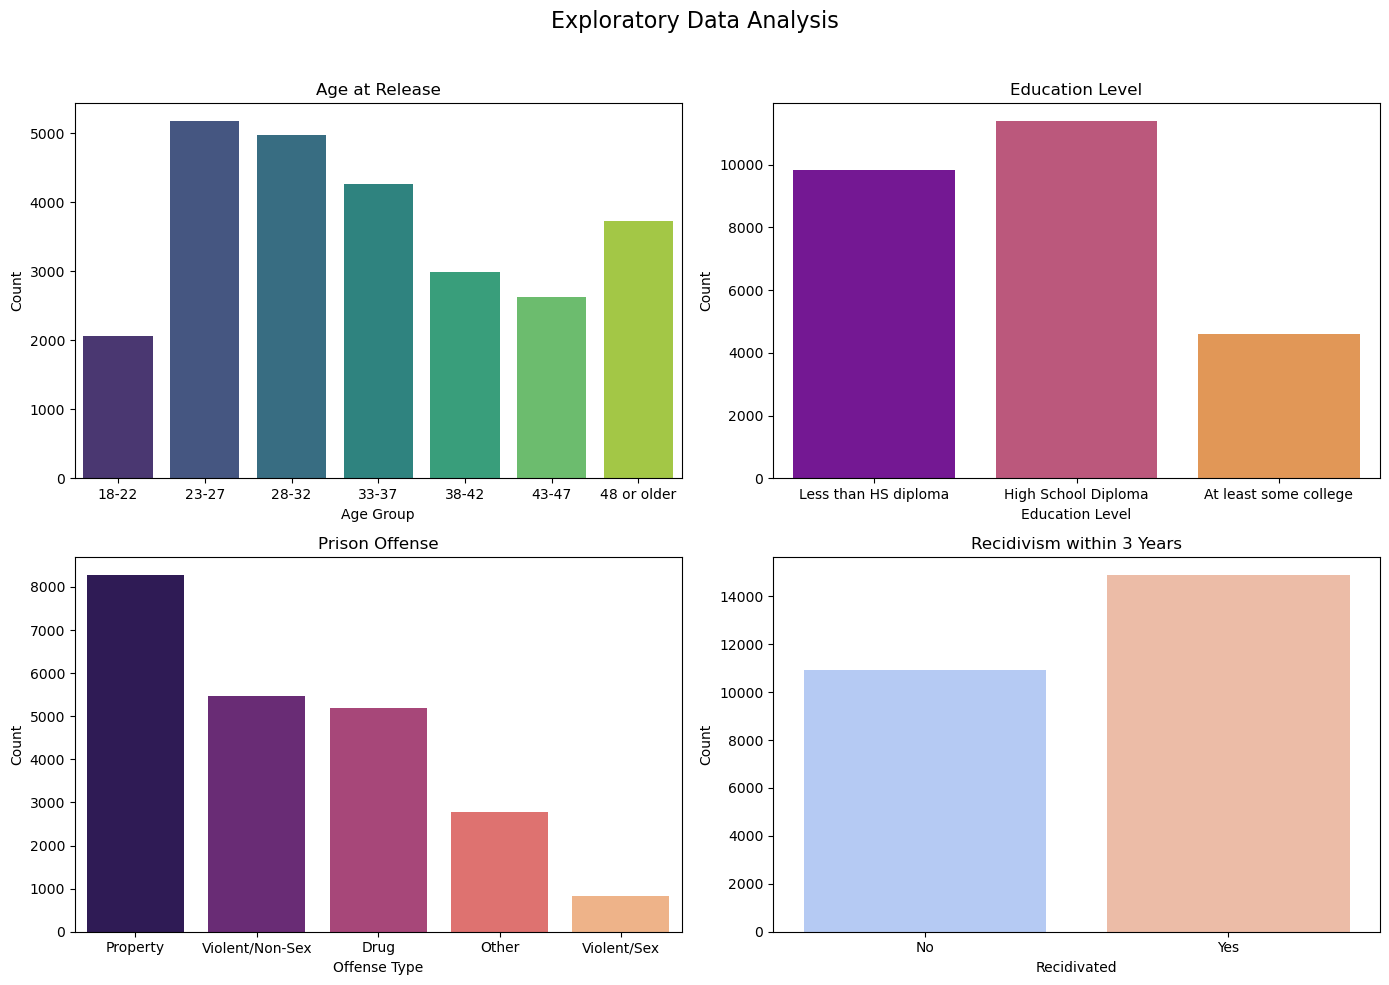

In [59]:
#Setting up the visualizations
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Exploratory Data Analysis', fontsize=16)

# Order for Age_at_Release
age_order = ['18-22', '23-27', '28-32', '33-37', '38-42', '43-47', '48 or older']

#Age at Release
sns.countplot(data=df, x='Age_at_Release', ax=axes[0, 0], palette='viridis', order= age_order)
axes[0, 0].set_title('Age at Release')
axes[0, 0].set_xlabel('Age Group')
axes[0, 0].set_ylabel('Count')

#Order for Education Level
edu_order = ['Less than HS diploma', 'High School Diploma', 'At least some college']

#Education Level
sns.countplot(data=df, x='Education_Level', ax=axes[0, 1], palette='plasma', order= edu_order)
axes[0, 1].set_title('Education Level')
axes[0, 1].set_xlabel('Education Level')
axes[0, 1].set_ylabel('Count')
axes[0, 1].tick_params(axis='x')

#Offense Order
offense_order = df['Prison_Offense'].value_counts().index

#Prison Offense
sns.countplot(data=df, x='Prison_Offense', ax=axes[1, 0], palette='magma', order= offense_order)
axes[1, 0].set_title('Prison Offense')
axes[1, 0].set_xlabel('Offense Type')
axes[1, 0].set_ylabel('Count')

#Recidivism within 3 years
sns.countplot(data=df, x='Recidivism_Within_3years', ax=axes[1, 1], palette='coolwarm')
axes[1, 1].set_title('Recidivism within 3 Years')
axes[1, 1].set_xlabel('Recidivated')
axes[1, 1].set_ylabel('Count')
axes[1, 1].set_xticklabels(['No', 'Yes'])

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()


This information simply helps to explore the data by showing the breakdown of prisoners (not the connection between the variable and recidivism). Here are some takeaways.


**Age at Release**
This data shows that there are relatively few prisoners released before the age 22 but a sharp increase of release from the ages of 23-32. The numbers then begin to steadily decrease as prisoners get older (ignoring the slight increase for 48+ as this is a larger age range than the rest). Because most releases are in this 10 year range and very few are released in their early 20s, I hypothesize that most are arrested in their early to mid twenties, serve around 5 years in prison, and are released in their mid 20s to 30s.


**Education Level**
Those in this data set were much more likely to not have an education. The number of prisoners who had at least some college education was significantly less than those who had only a high school diploma or less. With this information, I hypothesize that higher levels of education correlate with lower arrest rates.


**Prison Offense**
Here we see that most offenses are property related. Followed by violent/non-sex related offenses, and drug related offenses. The lack of violent/sex related offenses is very shocking to me. Is this because of a harsher sentencing on violent sex-related crimes, a lack of convictions on these crimes, or because of a lack of these crimes in general?


**Recidivism Within Three Years**
Because our main concern was recidivism within three years, it felt important to reiterate this visualization. While there is a large sum who do not recidivate within the three year period (approximately 11,000), a majority of prisoners do (approximately 15,000). It points to a major issue within the prison system that should be further evaluated.

